In [14]:
import numpy as np
import pandas as pd
from pathlib import Path

import sys
 
import matplotlib.pyplot as plt

In [ ]:
p = Path(r"C:\Users\ruben\OneDrive - Delft University of Technology\Documenten\Nanobiology 6\ARP\losses")

### Phantom tomogram analysis

In [5]:
phantom_loss_ddw = pd.read_csv(p / "phantom_ribcoh_ddw_loss.csv")
phantom_loss_ice = pd.read_csv(p / "phantom_ribcoh_ice_loss.csv")

   Iterations  Avg loss  Equivariant loss  Data-fidelity loss
0        1000  0.088554          0.005608            0.082946
1        2000  0.083246          0.004198            0.079048


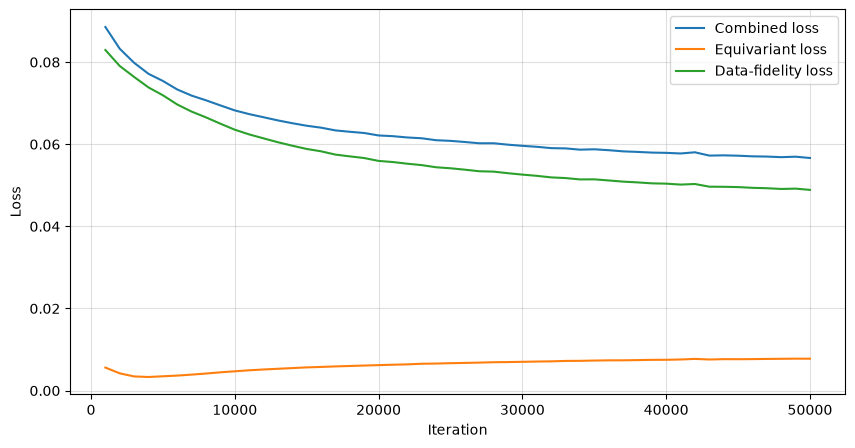

In [36]:
print(phantom_loss_ice.head(2))

df = phantom_loss_ice

plt.figure(figsize=(10, 5))
plt.plot(phantom_loss_ice["Iterations"], phantom_loss_ice["Avg loss"], label="Combined loss")
plt.plot(phantom_loss_ice["Iterations"], 
         phantom_loss_ice["Equivariant loss"],
         label="Equivariant loss")
plt.plot(phantom_loss_ice["Iterations"], 
         phantom_loss_ice["Data-fidelity loss"],
         label="Data-fidelity loss")
plt.legend()
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(alpha=0.4)

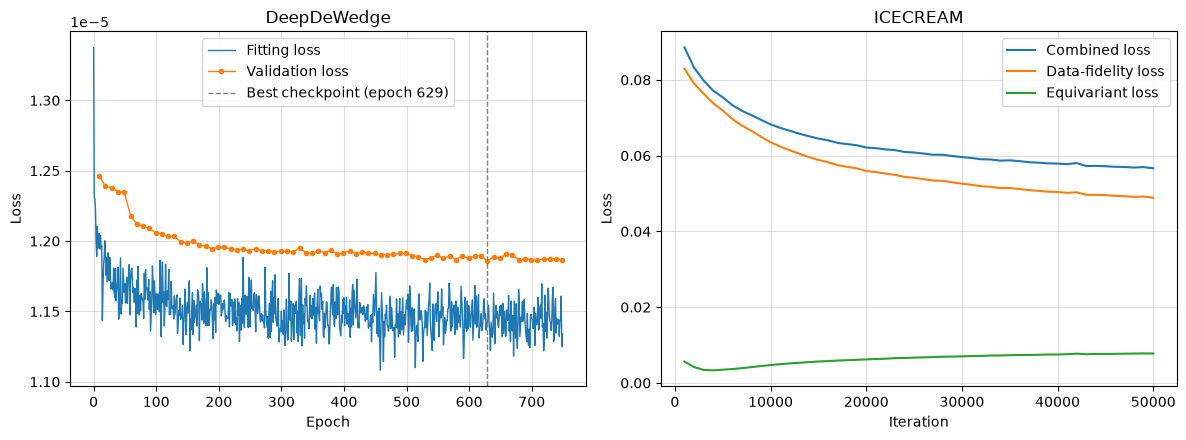

In [39]:
def plot_losses(ddw_csv, ice_csv, out_path=None, log_ice=False):
    ddw = ddw_csv
    ice = ice_csv

    # Lightning logs train and val on separate rows: split by which column is filled
    ddw_fit = ddw.dropna(subset=["fitting_loss"])
    ddw_val = ddw.dropna(subset=["val_loss"])
    ddw_val = ddw_val[ddw_val["step"] > 0]  # drop the untrained sanity-check value at step 0
    best = ddw_val.loc[ddw_val["val_loss"].idxmin()]

    fig, (ax_ddw, ax_ice) = plt.subplots(1, 2, figsize=(12, 4.5))

    ax_ddw.plot(ddw_fit["epoch"], ddw_fit["fitting_loss"], lw=1, label="Fitting loss")
    ax_ddw.plot(ddw_val["epoch"], ddw_val["val_loss"], "o-", ms=3, lw=1, label="Validation loss")
    ax_ddw.axvline(best["epoch"], color="grey", ls="--", lw=1,
                   label=f"Best checkpoint (epoch {int(best['epoch'])})")
    ax_ddw.set_title("DeepDeWedge")
    ax_ddw.set_xlabel("Epoch")

    ax_ice.plot(ice["Iterations"], ice["Avg loss"], label="Combined loss")
    ax_ice.plot(ice["Iterations"], ice["Data-fidelity loss"], label="Data-fidelity loss")
    ax_ice.plot(ice["Iterations"], ice["Equivariant loss"], label="Equivariant loss")
    ax_ice.set_title("ICECREAM")
    ax_ice.set_xlabel("Iteration")

    for ax in (ax_ddw, ax_ice):
        ax.set_ylabel("Loss")
        ax.grid(alpha=0.4)
        ax.legend()
    ax_ddw.ticklabel_format(axis="y", style="sci", scilimits=(-3, 3))
    if log_ice:
        ax_ice.set_yscale("log")

    fig.tight_layout()
    if out_path:
        fig.savefig(out_path, dpi=300)
    return fig


fig = plot_losses(phantom_loss_ddw, phantom_loss_ice)

In [67]:
"""Side-by-side training-loss plot: DeepDeWedge (left) and ICECREAM (right).

Usage in a notebook:
    from plot_losses import plot_losses
    fig = plot_losses("ddw_loss.csv", "ice_loss.csv", out_path="phantom_losses.png")

x_axis:
    "native"     DDW in epochs, ICECREAM in iterations
    "iteration"  both in optimiser steps (DDW 'step' column = ICECREAM iteration)
    "samples"    both in sub-tomograms seen (steps x batch size); pass both batch sizes
"""
import matplotlib.pyplot as plt
import pandas as pd

# DeepDeWedge in blues/teal, ICECREAM in warm colours, so the two never share a colour
DDW_FIT, DDW_VAL = "#1f4e79", "#2a9d8f"
ICE_TOTAL, ICE_DATA, ICE_EQUI = "#7b2d8b", "#e76f51", "#e9a03b"

def _read(path):
    # sep=None sniffs comma or tab; drop a saved pandas index column if present
    df = pd.read_csv(path, sep=None, engine="python")
    return df.loc[:, ~df.columns.str.startswith("Unnamed")]


def _smooth_plot(ax, x, y, color, label, window):
    """Raw points faint in the background, rolling mean on top."""
    ax.plot(x, y, color=color, lw=0.8, alpha=0.25)
    if window != 1:
        ax.plot(x, y.rolling(window, center=True, min_periods=1).mean(), color=color, lw=1.8,
                label=f"{label} ({window}-pt mean)")
    if window == 1:
        ax.plot(x, y.rolling(window, center=True, min_periods=1).mean(), color=color, lw=1.8,
                        label=f"{label}")


def plot_losses(ddw_csv, ice_csv, out_path=None, x_axis="native",
                ddw_used=None, ice_used=None, restart_ice=None,
                ddw_window=20, ice_window=5, log_ice=False):
    ddw = _read(ddw_csv)
    ice = _read(ice_csv)

    # Lightning logs train and val on separate rows: split by which column is filled
    ddw_fit = ddw.dropna(subset=["fitting_loss"])
    ddw_val = ddw.dropna(subset=["val_loss"])
    ddw_val = ddw_val[ddw_val["step"] > 0]  # drop the untrained sanity-check value at step 0

    if x_axis == "native":
        dx, ix = "epoch", "Iterations"
        dscale = iscale = 1
        dlabel, ilabel = "Epoch", "Iteration"
    else:
        raise ValueError("x_axis must be 'native', 'iteration' or 'samples'")

    fig, (ax_ddw, ax_ice) = plt.subplots(1, 2, figsize=(12, 4.5),
                                         sharex=(x_axis != "native"))

    # Left: DeepDeWedge
    _smooth_plot(ax_ddw, ddw_fit[dx] * dscale, ddw_fit["fitting_loss"], DDW_FIT,
                 "Fitting loss", ddw_window)
    ax_ddw.plot(ddw_val[dx] * dscale, ddw_val["val_loss"], "o-", ms=3, lw=1,
                color=DDW_VAL, label="Validation loss")
    if ddw_used is not None:
        ax_ddw.axvline(ddw_used * dscale, color="grey", ls="--", lw=1,
                    label=f"Used checkpoint (epoch {int(ddw_used)})")
    ax_ddw.set_title("DeepDeWedge")
    ax_ddw.set_xlabel(dlabel)
    ax_ddw.ticklabel_format(axis="y", style="sci", scilimits=(-3, 3))

    # Right: ICECREAM
    x = ice[ix] * iscale
    _smooth_plot(ax_ice, x, ice["Avg loss"], ICE_TOTAL, "Combined loss", ice_window)
    _smooth_plot(ax_ice, x, ice["Data-fidelity loss"], ICE_DATA, "Data-fidelity loss", ice_window)
    _smooth_plot(ax_ice, x, ice["Equivariant loss"], ICE_EQUI, "Equivariant loss", ice_window)
    ax_ice.set_title("ICECREAM")
    ax_ice.set_xlabel(ilabel)
    if log_ice:
        ax_ice.set_yscale("log")
    if ice_used is not None:
        ax_ice.axvline(ice_used *dscale, color="grey", ls="--", lw=1,
                       label=f"Used checkpoint (iteration {int(ice_used)})")
    if restart_ice is not None:
        ax_ice.axvline(5000, ls=":", color="red", lw=1,
                       label=f"Restart (iteration {int(restart_ice)})")
    for ax in (ax_ddw, ax_ice):
        ax.set_ylabel("Loss")
        ax.grid(alpha=0.4)
        ax.legend(fontsize=9)

    fig.tight_layout()
    if out_path:
        fig.savefig(out_path, dpi=600)
    return fig


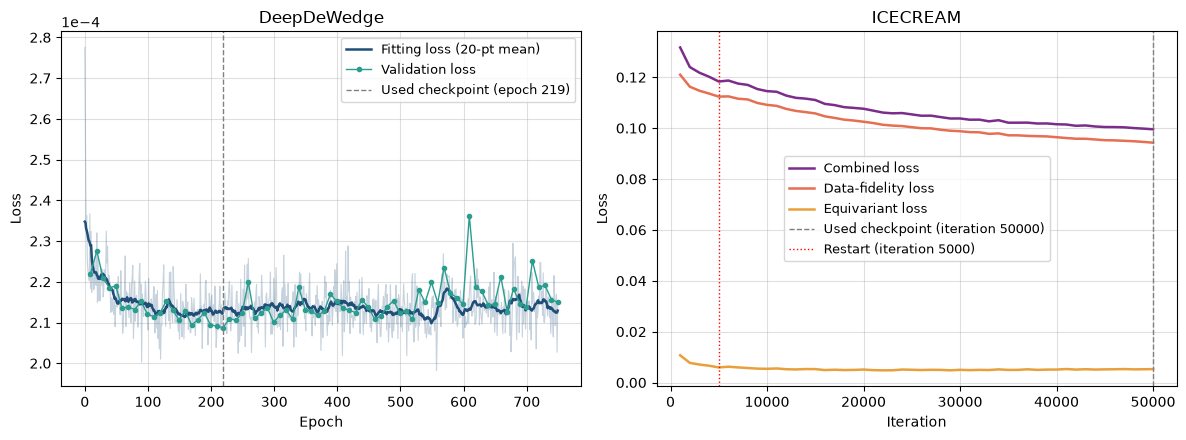

In [69]:
p_ddw =p / "ddw_metrics_inttilts_108.csv"
p_ice = p / "ice_metrics_inttilts_108_combined.csv"

f = plot_losses(p_ddw, p_ice, ice_window=1, x_axis= "native", 
                ddw_used=219, ice_used=50000, restart_ice = 5000, 
                out_path="Inttilt_loss.png")